<a href="https://colab.research.google.com/github/Ash-Amarnath/EMJM_Assignments/blob/main/Regression_Exploration_V1_Neurons.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW 1: Regression Analysis of Orientation Tuning in Monkey V1 Neurons

In this notebook, I analyze extracellular recordings from neurons in macaque primary visual cortex (V1). During the experiment, drifting grating stimuli were presented at eight different orientations, and spike activity was recorded from many neurons simultaneously.

The goal is to move from raw spike times to a meaningful neuronal response measure, construct orientation-tuning curves, and then compare several regression models:

1. Polynomial regression models
2. A Gaussian orientation-tuning model
3. A circular von Mises orientation-tuning model

The main question is: **how well can each model describe the relationship between stimulus orientation and neuronal firing rate?**

I also care about more than just fitting the observed data. A model with the lowest training error is not necessarily the best model, especially if it becomes overly flexible and starts fitting noise. Therefore, I compare both the fit quality and the interpretability of each model.

**Dataset:**  
The data are loaded from the Dryad repository:  
https://datadryad.org/dataset/doi:10.5061/dryad.h9w0vt4s0

**Notebook structure:**

1. Load and inspect the raw dataset
2. Convert spike counts into firing rates and construct tuning curves
3. Select a primary neuron using an explicit SNR and tuning-range criterion
4. Fit polynomial models
5. Fit a Gaussian tuning model
6. Fit a circular von Mises model
7. Compare models and evaluate them on noisier neurons

In [53]:
# ==============================================================================
# CELL 1: SETUP & IMPORTS
# ==============================================================================
import h5py
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Exploratory Inspection

Before doing any analysis, I first inspect the structure of the dataset. This is important because the raw `.mat` file contains a three-dimensional spike array, and I need to confirm what each dimension represents.

Specifically, I check:

- The total number of trials
- The number of time bins in each trial
- The number of simultaneously recorded neurons
- The stimulus condition associated with each trial
- Whether the eight orientations are balanced across trials

The spike matrix has the shape:
$
[\text{trials}, \text{time bins in ms}, \text{neurons}]
$

Each entry tells us whether a spike occurred in a given millisecond for a given neuron on a given trial.

I also print the unique stimulus indices and the number of trials for each one. This lets me verify that every orientation was presented equally often, which matters because the mean tuning curve for each orientation should be based on the same number of trials.

Finally, I preview a small part of the raw spike train. At this stage, the values are mostly zeros with occasional ones, because each millisecond bin records whether a spike occurred.

In [54]:
# ==============================================================================
# CELL 2: DATASET SUMMARY & EXPLORATORY INSPECTION
# ==============================================================================
mat_file_path = '/content/drive/MyDrive/dataset/dataset/dataset1/107l003p143_spikes.mat'

# Load the HDF5 (.mat) dataset file
with h5py.File(mat_file_path, 'r') as f:
    stim = f['stim'][:].flatten().astype(int)
    spikes_ref = f['spikes'][:].flat[0]
    spikes_data = f[spikes_ref][:]

# Print dataset summary information
print("--- Dataset Summary ---")
print(f"Total Trials: {stim.shape[0]}")
print(f"Spike Matrix Shape (Trials, Timebins in ms, Neurons): {spikes_data.shape}")
print(f"Data Type of Spike Matrix: {spikes_data.dtype}")

# Check trial balance across unique orientation indices
unique_stims, trial_counts = np.unique(stim, return_counts=True)
print("\n--- Stimulus Orientation Balance ---")
print(f"Unique Orientations Found: {unique_stims.tolist()}")
for s, count in zip(unique_stims, trial_counts):
    print(f"Orientation Index {s}: {count} trials")

# Preview raw spike data (similar to a pandas .head() preview for the first 10 timebins of trial 0)
print("\n--- Raw Spike Train Preview (First 10 ms of Trial 0 for Neuron #0) ---")
print(spikes_data[0, :10, 0])


--- Dataset Summary ---
Total Trials: 3200
Spike Matrix Shape (Trials, Timebins in ms, Neurons): (3200, 1280, 111)
Data Type of Spike Matrix: float64

--- Stimulus Orientation Balance ---
Unique Orientations Found: [1, 2, 3, 4, 5, 6, 7, 8]
Orientation Index 1: 400 trials
Orientation Index 2: 400 trials
Orientation Index 3: 400 trials
Orientation Index 4: 400 trials
Orientation Index 5: 400 trials
Orientation Index 6: 400 trials
Orientation Index 7: 400 trials
Orientation Index 8: 400 trials

--- Raw Spike Train Preview (First 10 ms of Trial 0 for Neuron #0) ---
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## Task 1: From Raw Spikes to Orientation-Tuning Curves

The raw data contain spike occurrences at every millisecond of each trial. To summarize each trial, I count the total number of spikes during the 1280 ms stimulus presentation period.

Because the stimulus lasts 1.28 seconds, I convert spike counts into firing rate in Hz:

$$
\text{Firing rate} = \frac{\text{spike count}}{1.28}
$$

I also compute the standard error of the mean (SEM) for each orientation:

$$
SEM = \frac{\text{standard deviation across trials}}{\sqrt{n}}
$$

To select the primary neuron, I compute an SNR index for every neuron:

$$
SNR = \frac{\text{tuning range}}{\text{mean SEM}}
$$

Here, the tuning range is the difference between the largest and smallest mean firing rates across the eight orientations. A high SNR means that the neuron’s orientation-dependent signal is large relative to its trial-to-trial variability.

A high SNR means that the neuron’s orientation-dependent signal is large relative to its trial-to-trial variability.

Second, among the neurons in the top 10% by SNR, I select the neuron with the **largest tuning range**.

This ensures that the selected neuron has both:

1. A reliable response, because its tuning signal is large compared with its noise
2. A clear orientation dependence, because its firing rate changes substantially across orientations

I also plot the three highest-SNR neurons and the three lowest-SNR neurons. This helps show the difference between strongly tuned, reliable neurons and weakly tuned or noisy neurons.

The selected neuron is then used for all later regression analyses.

--- Task 1 Summary Metrics ---
Total Neurons Analyzed: 111
Total Trials: 3200
Orientations (degrees): [0.0, 22.5, 45.0, 67.5, 90.0, 112.5, 135.0, 157.5]

--- Exploratory SNR Screening ---
Top 3 Highest-SNR Neurons: [81, 44, 89]
Bottom 3 Lowest-SNR Neurons: [108, 69, 41]

--- Primary Neuron Selection ---
SNR threshold (90th percentile): 142.13
Number of eligible high-SNR neurons: 12
Selected Primary Neuron: #101
Selected neuron SNR: 190.79
Selected neuron tuning range: 85.13 Hz
Selected neuron mean SEM: 0.45 Hz

--- Exploratory Neuron Summary ---


Neuron,Group,Mean Firing Rate (Hz),Tuning Range (Hz),Mean SEM (Hz),SNR
#81,Highest SNR,27.49,60.34,0.26,228.21
#44,Highest SNR,52.17,74.54,0.38,197.52
#89,Highest SNR,3.51,16.20,0.08,191.29
#108,Lowest SNR,9.35,2.76,0.21,13.21
#69,Lowest SNR,2.51,0.94,0.08,11.54
#41,Lowest SNR,30.12,3.80,0.35,10.81


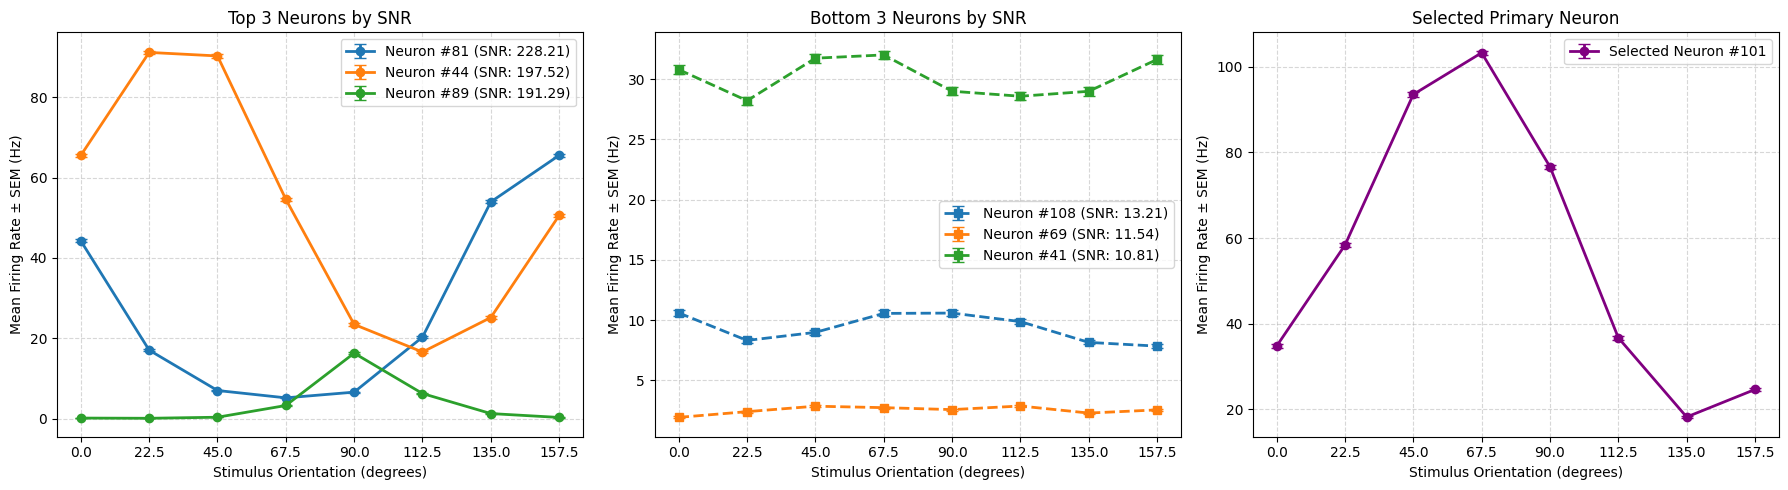

In [55]:
# =============================================================================
# CELL 3: TASK 1 - TUNING CURVES, SEM, SNR, & NEURON SELECTION
# =============================================================================

# Count spikes during the 1280 ms stimulus window and convert to firing rate in Hz
spike_counts_per_trial = np.sum(spikes_data, axis=1)
firing_rates_per_trial = spike_counts_per_trial / 1.28

# Map stimulus indices to orientation in degrees
index_to_degree = {
    1: 0.0,
    2: 22.5,
    3: 45.0,
    4: 67.5,
    5: 90.0,
    6: 112.5,
    7: 135.0,
    8: 157.5
}

unique_stims = np.unique(stim)
mapped_degrees = np.array([index_to_degree[int(s)] for s in unique_stims])

# Mean tuning curve for every neuron and orientation
tuning_curves = np.array([
    firing_rates_per_trial[stim == s].mean(axis=0)
    for s in unique_stims
])

# Standard error of the mean across trials
sems = np.array([
    firing_rates_per_trial[stim == s].std(axis=0, ddof=1) / np.sqrt(np.sum(stim == s))
    for s in unique_stims
])

# Exploratory measures:
# tuning range = strength of orientation modulation
# mean SEM = trial-to-trial noise
# SNR = tuning range divided by mean SEM
tuning_range = np.ptp(tuning_curves, axis=0)
mean_sem = sems.mean(axis=0)
snr = tuning_range / np.maximum(mean_sem, 1e-12)

# ---------------------------------------------------------------------------
# EXPLORATORY NEURON SCREENING
# ---------------------------------------------------------------------------

# Highest-SNR neurons: reliable, low-noise responses
sorted_by_snr = np.argsort(snr)[::-1]
top_3_snr = np.array([int(i) for i in sorted_by_snr[:3]])

# Lowest-SNR neurons: noisiest / weakest tuning
bottom_3_snr = np.array([int(i) for i in sorted_by_snr[-3:]])

# ---------------------------------------------------------------------------
# PRIMARY NEURON SELECTION
# ---------------------------------------------------------------------------
# Select a neuron with both:
#   1. High SNR, meaning the tuning signal is large relative to trial noise
#   2. Large orientation-tuning range, meaning a clear change in firing rate
#      across orientations
#
# We first keep neurons in the top 10% by SNR, then choose the one with the
# largest tuning range. This avoids selecting a neuron that merely has low
# noise but little orientation dependence.

snr_threshold = np.percentile(snr, 90)
eligible_neurons = np.where(snr >= snr_threshold)[0]

best_neuron = int(eligible_neurons[np.argmax(tuning_range[eligible_neurons])])

x = mapped_degrees
y = tuning_curves[:, best_neuron]
x_fine = np.linspace(0, 157.5, 500)

print("--- Task 1 Summary Metrics ---")
print(f"Total Neurons Analyzed: {spikes_data.shape[2]}")
print(f"Total Trials: {len(stim)}")
print(f"Orientations (degrees): {mapped_degrees.tolist()}")

print("\n--- Exploratory SNR Screening ---")
print(f"Top 3 Highest-SNR Neurons: {top_3_snr.tolist()}")
print(f"Bottom 3 Lowest-SNR Neurons: {bottom_3_snr.tolist()}")

print("\n--- Primary Neuron Selection ---")
print(f"SNR threshold (90th percentile): {snr_threshold:.2f}")
print(f"Number of eligible high-SNR neurons: {len(eligible_neurons)}")
print(f"Selected Primary Neuron: #{best_neuron}")
print(f"Selected neuron SNR: {snr[best_neuron]:.2f}")
print(f"Selected neuron tuning range: {tuning_range[best_neuron]:.2f} Hz")
print(f"Selected neuron mean SEM: {mean_sem[best_neuron]:.2f} Hz")

# Summary table for the six exploratory neurons
selected_neurons = np.concatenate([top_3_snr, bottom_3_snr])

summary_rows = []
for idx in selected_neurons:
    summary_rows.append({
        "Neuron": f"#{idx}",
        "Group": "Highest SNR" if idx in top_3_snr else "Lowest SNR",
        "Mean Firing Rate (Hz)": tuning_curves[:, idx].mean(),
        "Tuning Range (Hz)": tuning_range[idx],
        "Mean SEM (Hz)": mean_sem[idx],
        "SNR": snr[idx]
    })

neuron_summary = pd.DataFrame(summary_rows)

print("\n--- Exploratory Neuron Summary ---")
display(
    neuron_summary.style.format({
        "Mean Firing Rate (Hz)": "{:.2f}",
        "Tuning Range (Hz)": "{:.2f}",
        "Mean SEM (Hz)": "{:.2f}",
        "SNR": "{:.2f}"
    }).hide(axis="index")
)

# Plot the three highest-SNR neurons
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx in top_3_snr:
    axes[0].errorbar(
        mapped_degrees,
        tuning_curves[:, idx],
        yerr=sems[:, idx],
        fmt="o-",
        linewidth=2,
        capsize=4,
        label=f"Neuron #{idx} (SNR: {snr[idx]:.2f})"
    )

axes[0].set_title("Top 3 Neurons by SNR", fontsize=12)
axes[0].set_xlabel("Stimulus Orientation (degrees)", fontsize=10)
axes[0].set_ylabel("Mean Firing Rate ± SEM (Hz)", fontsize=10)
axes[0].set_xticks(mapped_degrees)
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot the three lowest-SNR neurons
for idx in bottom_3_snr:
    axes[1].errorbar(
        mapped_degrees,
        tuning_curves[:, idx],
        yerr=sems[:, idx],
        fmt="s--",
        linewidth=2,
        capsize=4,
        label=f"Neuron #{idx} (SNR: {snr[idx]:.2f})"
    )

axes[1].set_title("Bottom 3 Neurons by SNR", fontsize=12)
axes[1].set_xlabel("Stimulus Orientation (degrees)", fontsize=10)
axes[1].set_ylabel("Mean Firing Rate ± SEM (Hz)", fontsize=10)
axes[1].set_xticks(mapped_degrees)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

# Plot the selected primary neuron
axes[2].errorbar(
    mapped_degrees,
    tuning_curves[:, best_neuron],
    yerr=sems[:, best_neuron],
    fmt="o-",
    color="purple",
    linewidth=2,
    capsize=4,
    label=f"Selected Neuron #{best_neuron}"
)

axes[2].set_title("Selected Primary Neuron", fontsize=12)
axes[2].set_xlabel("Stimulus Orientation (degrees)", fontsize=10)
axes[2].set_ylabel("Mean Firing Rate ± SEM (Hz)", fontsize=10)
axes[2].set_xticks(mapped_degrees)
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Task 2: Polynomial Regression

Before using a biologically motivated model, I first fit several polynomial regression models to the selected neuron’s tuning curve.

The four models are:
$$
R(\theta) = \beta_0 + \beta_1\theta
$$

$$
R(\theta) = \beta_0 + \beta_1\theta + \beta_2\theta^2 + \beta_3\theta^3
$$

$$
R(\theta) = \beta_0 + \beta_1\theta + \beta_2\theta^2 + \beta_3\theta^3 + \beta_4\theta^4
$$

$$
R(\theta) = \beta_0 + \beta_1\theta + \beta_2\theta^2 + \beta_3\theta^3 + \beta_4\theta^4 + \beta_5\theta^5 + \beta_6\theta^6 + \beta_7\theta^7
$$

For each model, I calculate the training mean squared error:
$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$


Here, $\theta$ is the stimulus orientation in degrees, and R $(\theta)$ is the predicted mean firing rate.

The polynomial degree controls the flexibility of the model:

- Degree 1 fits a straight line
- Degree 3 can produce a curved shape
- Degree 4 can capture more complex curvature
- Degree 7 has enough flexibility to pass through all eight data points

For each model, I calculate the training mean squared error:
$$
[
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2
]
$$
where $y_i$ is the observed mean firing rate and $\hat{y}_i$ is the model prediction.

The degree-7 polynomial has eight coefficients and there are only eight orientation conditions. Therefore, it can interpolate every data point exactly and will usually have an MSE close to zero. This does **not** mean it is the best model. It likely overfits the observed means and may behave poorly between or outside the measured orientations.

Polynomial regression is useful as a flexible baseline, but its coefficients do not have a direct biological interpretation. They do not correspond to quantities such as baseline firing rate, preferred orientation, tuning width, or response amplitude.

--- Polynomial Regression Results for Neuron #101 ---
Degree 1 Model -> MSE: 751.4296 Hz^2
Degree 3 Model -> MSE: 101.8959 Hz^2
Degree 4 Model -> MSE: 16.3008 Hz^2
Degree 7 Model -> MSE: 0.0000 Hz^2


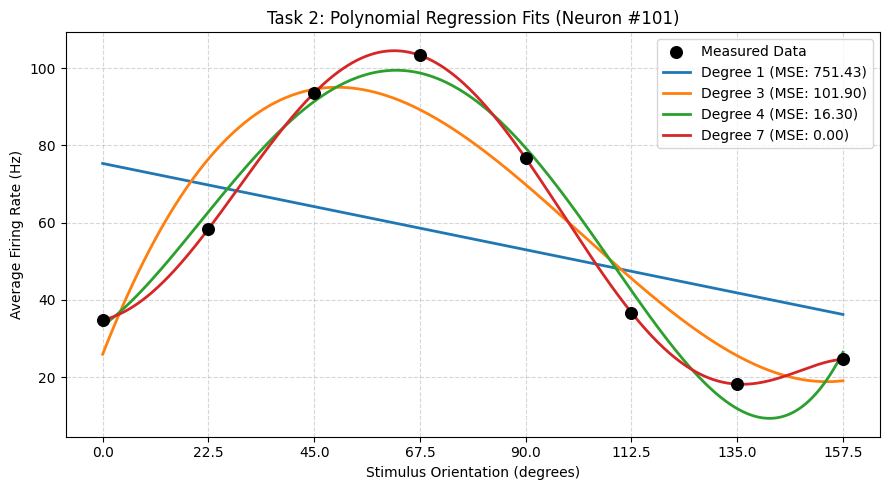

In [56]:
# =============================================================================
# CELL 4: TASK 2 - POLYNOMIAL REGRESSION
# =============================================================================

x = mapped_degrees
y = tuning_curves[:, best_neuron]
degrees = [1, 3, 4, 7]
x_fine = np.linspace(0, 157.5, 500)

polynomial_mses = {}
polynomial_coeffs = {}

plt.figure(figsize=(9, 5))
plt.scatter(x, y, color="black", s=70, zorder=5, label="Measured Data")

print(f"--- Polynomial Regression Results for Neuron #{best_neuron} ---")

for deg in degrees:
    coeffs = np.polyfit(x, y, deg)
    y_pred = np.polyval(coeffs, x)
    mse = np.mean((y - y_pred) ** 2)

    polynomial_coeffs[deg] = coeffs
    polynomial_mses[deg] = mse

    y_fine = np.polyval(coeffs, x_fine)
    plt.plot(
        x_fine,
        y_fine,
        linewidth=2,
        label=f"Degree {deg} (MSE: {mse:.2f})"
    )

    print(f"Degree {deg} Model -> MSE: {mse:.4f} Hz^2")

plt.title(f"Task 2: Polynomial Regression Fits (Neuron #{best_neuron})")
plt.xlabel("Stimulus Orientation (degrees)")
plt.ylabel("Average Firing Rate (Hz)")
plt.xticks(x)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Task 3: Nonlinear Gaussian Tuning Model

Polynomials can approximate the shape of a tuning curve, but they do not naturally describe the biological structure of orientation tuning. I therefore fit a Gaussian model:

$$
[
R(\theta) = B + A\exp\left(-\frac{(\theta-\mu)^2}{2\sigma^2}\right)
]
$$

This model has four parameters:

- \(B\): baseline firing rate
- \(A\): response amplitude above baseline
- $(\mu)$: preferred orientation
- $(\sigma)$: tuning width

Unlike polynomial coefficients, each parameter has a direct biological interpretation.

- \(B\) estimates the neuron’s firing when the stimulus is far from its preferred orientation.
- \(A\) measures how strongly the neuron increases its firing above baseline.
- $(\mu)$ estimates the orientation that produces the strongest response.
- $(\sigma)$ describes how sharply the neuron is tuned. A small $\sigma$ means narrow, selective tuning; a large $\sigma$ means broader tuning.

I fit the model using nonlinear least squares and compare its MSE with the polynomial models. Even if a polynomial achieves a similar or lower MSE, the Gaussian model may be preferable because it is constrained to a single-peaked tuning curve and has interpretable parameters.

One limitation is that this Gaussian model treats orientation as an ordinary linear variable. It does not yet account for the fact that orientation is circular: $0^\circ$ and $180^\circ$ represent the same orientation.

--- Task 3: Optimized Gaussian Parameters ---
Response Amplitude Above Baseline (A): 85.66 Hz
Preferred Orientation (mu): 60.65 degrees
Tuning Width (sigma): 30.03 degrees
Baseline Firing Rate (B): 20.19 Hz
Predicted Peak Firing Rate (A + B): 105.85 Hz
Gaussian Model MSE: 10.5453 Hz^2


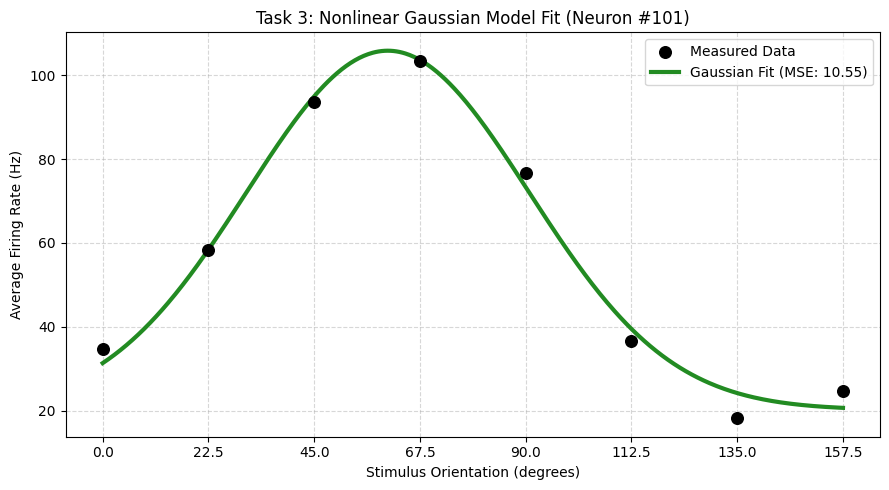

In [57]:
# =============================================================================
# CELL 5: TASK 3 - NONLINEAR GAUSSIAN MODEL
# =============================================================================

def gaussian_tuning(theta, A, mu, sigma, B):
    """
    Gaussian orientation-tuning model:
    R(theta) = B + A * exp(-(theta - mu)^2 / (2 * sigma^2))

    A: response amplitude above baseline
    mu: preferred orientation
    sigma: tuning width
    B: baseline firing rate
    """
    return A * np.exp(-((theta - mu) ** 2) / (2 * sigma ** 2)) + B


initial_guess = [
    np.max(y) - np.min(y),
    mapped_degrees[np.argmax(y)],
    20.0,
    np.min(y)
]

popt_g, _ = curve_fit(gaussian_tuning, x, y, p0=initial_guess)
A_g, mu_g, sigma_g, B_g = popt_g

y_pred_g = gaussian_tuning(x, *popt_g)
mse_g = np.mean((y - y_pred_g) ** 2)

print("--- Task 3: Optimized Gaussian Parameters ---")
print(f"Response Amplitude Above Baseline (A): {A_g:.2f} Hz")
print(f"Preferred Orientation (mu): {mu_g:.2f} degrees")
print(f"Tuning Width (sigma): {sigma_g:.2f} degrees")
print(f"Baseline Firing Rate (B): {B_g:.2f} Hz")
print(f"Predicted Peak Firing Rate (A + B): {A_g + B_g:.2f} Hz")
print(f"Gaussian Model MSE: {mse_g:.4f} Hz^2")

y_fine_g = gaussian_tuning(x_fine, *popt_g)

plt.figure(figsize=(9, 5))
plt.scatter(x, y, color="black", s=70, zorder=5, label="Measured Data")
plt.plot(
    x_fine,
    y_fine_g,
    color="forestgreen",
    linewidth=3,
    label=f"Gaussian Fit (MSE: {mse_g:.2f})"
)
plt.title(f"Task 3: Nonlinear Gaussian Model Fit (Neuron #{best_neuron})")
plt.xlabel("Stimulus Orientation (degrees)")
plt.ylabel("Average Firing Rate (Hz)")
plt.xticks(x)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Task 4: Accounting for Circular Orientation with a von Mises Model

Orientation is a circular variable. Although we represent orientations numerically from \(0^\circ\) to \(180^\circ\), the two endpoints are actually the same orientation. A stimulus at \(0^\circ\) and a stimulus at \(180^\circ\) have the same orientation.

This creates a problem for the Gaussian model. A standard Gaussian is defined on an infinite linear axis, so it treats \(0^\circ\) and \(180^\circ\) as far apart. If a neuron’s true preferred orientation is near the boundary, the Gaussian cannot properly wrap the tuning curve across that boundary.

To handle this, I fit a von Mises tuning model:
$$
[
R(\theta) = B + A\exp\left[\kappa\cos(2(\theta-\mu))\right]
]
$$

The important part is the factor of 2:
$$
[
\cos(2(\theta-\mu))
]
$$

A normal cosine repeats every $360^\circ$. But orientation repeats every $180^\circ$, because $0^\circ$ and $180^\circ$ are equivalent. Multiplying the angle difference by 2 makes the cosine repeat every $180^\circ$, which matches the circular structure of orientation.

The parameters are:

- \(B\): baseline firing rate
- \(A\): response amplitude
- $(\mu)$: preferred orientation
- $(\kappa)$: concentration parameter

A larger $\kappa$ produces narrower, more selective tuning. A smaller $\kappa$ produces broader tuning.

I fit this model to the same neuron and compare its MSE with the Gaussian model. For a neuron whose preferred orientation is far from the $0^\circ$ $180^\circ$ boundary, the two fits may look similar. However, the von Mises model is still more principled because it explicitly respects the circular nature of orientation.

--- Optimized von Mises Model ---
Baseline (B): 0.00 Hz
Amplitude (A): 47.86
Preferred Orientation (mu): 60.60 degrees
Concentration (kappa): 0.80
Training MSE: 10.0737 Hz^2


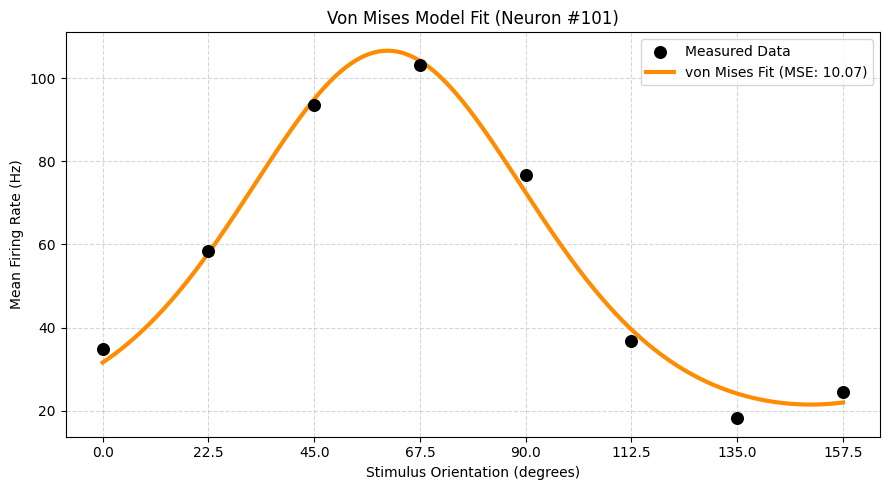

In [58]:

# ==============================================================================
# CELL 6: TASK 4 - CIRCULAR STATISTICS (VON MISES MODEL)
# ==============================================================================

# Orientation is circular: 0 degrees and 180 degrees represent the same
# orientation. Multiplying angles by 2 accounts for this periodicity.

def von_mises_tuning(theta, B, A, mu, kappa):
    theta_rad = np.radians(theta) * 2
    mu_rad = np.radians(mu) * 2
    return B + A * np.exp(kappa * np.cos(theta_rad - mu_rad))


initial_guess_vm = [
    max(0, np.min(y) - 1),
    max(np.ptp(y), 1),
    mapped_degrees[np.argmax(y)],
    1.0
]

popt_vm, _ = curve_fit(
    von_mises_tuning,
    x,
    y,
    p0=initial_guess_vm,
    bounds=([0, 0, 0, 0], [100, 200, 180, 20]),
    maxfev=20000
)

B_vm, A_vm, mu_vm, kappa_vm = popt_vm

y_pred_vm = von_mises_tuning(x, *popt_vm)
mse_vm = np.mean((y - y_pred_vm) ** 2)
y_fine_vm = von_mises_tuning(x_fine, *popt_vm)

print("--- Optimized von Mises Model ---")
print(f"Baseline (B): {B_vm:.2f} Hz")
print(f"Amplitude (A): {A_vm:.2f}")
print(f"Preferred Orientation (mu): {mu_vm:.2f} degrees")
print(f"Concentration (kappa): {kappa_vm:.2f}")
print(f"Training MSE: {mse_vm:.4f} Hz^2")

plt.figure(figsize=(9, 5))
plt.scatter(x, y, color='black', s=70, label='Measured Data', zorder=5)
plt.plot(
    x_fine, y_fine_vm,
    color='darkorange', linewidth=3,
    label=f'von Mises Fit (MSE: {mse_vm:.2f})'
)
plt.title(f"Von Mises Model Fit (Neuron #{best_neuron})")
plt.xlabel("Stimulus Orientation (degrees)")
plt.ylabel("Mean Firing Rate (Hz)")
plt.xticks(x)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## Task 5: Comparing Models

So far, I have fit six models to the selected neuron:

1. Linear polynomial
2. Third-order polynomial
3. Fourth-order polynomial
4. Seventh-order polynomial
5. Gaussian tuning model
6. Circular von Mises tuning model

In this cell, I summarize their number of parameters, training MSE, biological interpretability, and whether they account for the circular nature of orientation.

The number of parameters matters because more parameters generally mean more flexibility. A model with more flexibility can often achieve a lower training MSE, but it may also be more likely to overfit.

The key distinction is between:

- **Training MSE:** how well the model fits the eight observed mean responses
- **Generalization:** how well the model would predict responses to new stimulus orientations

A degree-7 polynomial can have zero training error because it has enough coefficients to pass through every observed point. However, that does not mean it captures the true underlying tuning curve. It may simply be fitting noise or particular fluctuations in this neuron’s data.

The Gaussian and von Mises models are preferable when the goal is biological interpretation because their parameters correspond to meaningful features of orientation tuning. The von Mises model is especially appropriate because it explicitly treats orientation as circular.

In [59]:
# =============================================================================
# CELL 7: TASK 5 - MODEL COMPARISON
# =============================================================================

model_names = [
    "Linear (Degree 1)",
    "3rd-Order Polynomial",
    "4th-Order Polynomial",
    "7th-Order Polynomial",
    "Gaussian Model",
    "von Mises Model (Circular)"
]

comparison_table = pd.DataFrame({
    "Regression Model": model_names,
    "Number of Parameters": [2, 4, 5, 8, 4, 4],
    "Training MSE (Hz^2)": [
        polynomial_mses[1],
        polynomial_mses[3],
        polynomial_mses[4],
        polynomial_mses[7],
        mse_g,
        mse_vm
    ],
    "Biologically Interpretable?": [
        "No", "No", "No", "No", "Yes", "Yes"
    ],
    "Accounts for Circular Seam?": [
        "No", "No", "No", "No", "No", "Yes"
    ]
})

print(f"--- Model Performance Comparison (Primary Neuron #{best_neuron}) ---")
display(
    comparison_table.style.format({
        "Training MSE (Hz^2)": "{:.4f}"
    }).hide(axis="index")
)

--- Model Performance Comparison (Primary Neuron #101) ---


Regression Model,Number of Parameters,Training MSE (Hz^2),Biologically Interpretable?,Accounts for Circular Seam?
Linear (Degree 1),2,751.4296,No,No
3rd-Order Polynomial,4,101.8959,No,No
4th-Order Polynomial,5,16.3008,No,No
7th-Order Polynomial,8,0.0000,No,No
Gaussian Model,4,10.5453,Yes,No
von Mises Model (Circular),4,10.0737,Yes,Yes


## Comparing Models on Noisier Neurons

A model that fits one strongly tuned neuron well may not be equally useful for neurons with weaker or noisier responses. To test this, I select the two neurons with the lowest SNR values from the exploratory analysis in Task 1.

These neurons have relatively small tuning ranges compared with their trial-to-trial variability. Their tuning curves are therefore less clean, and it is harder to distinguish true orientation dependence from noise.

For each noisy neuron, I fit three models:

1. Linear regression
2. Gaussian tuning model
3. Circular von Mises tuning model

The Gaussian model is included because the assignment requires it, and it provides a biologically interpretable nonlinear baseline. The von Mises model is included because it accounts for the circular nature of orientation. The linear model is included as a simple reference model.

I compare their training MSE values and plot the fitted curves against the measured tuning curves.

Because these neurons are noisier, a flexible model may achieve a lower training error by fitting random fluctuations. However, that does not necessarily mean it will generalize better to new stimulus orientations. For prediction, I would generally prefer a constrained, interpretable model such as the Gaussian or von Mises model over a high-degree polynomial, especially when the data are noisy.

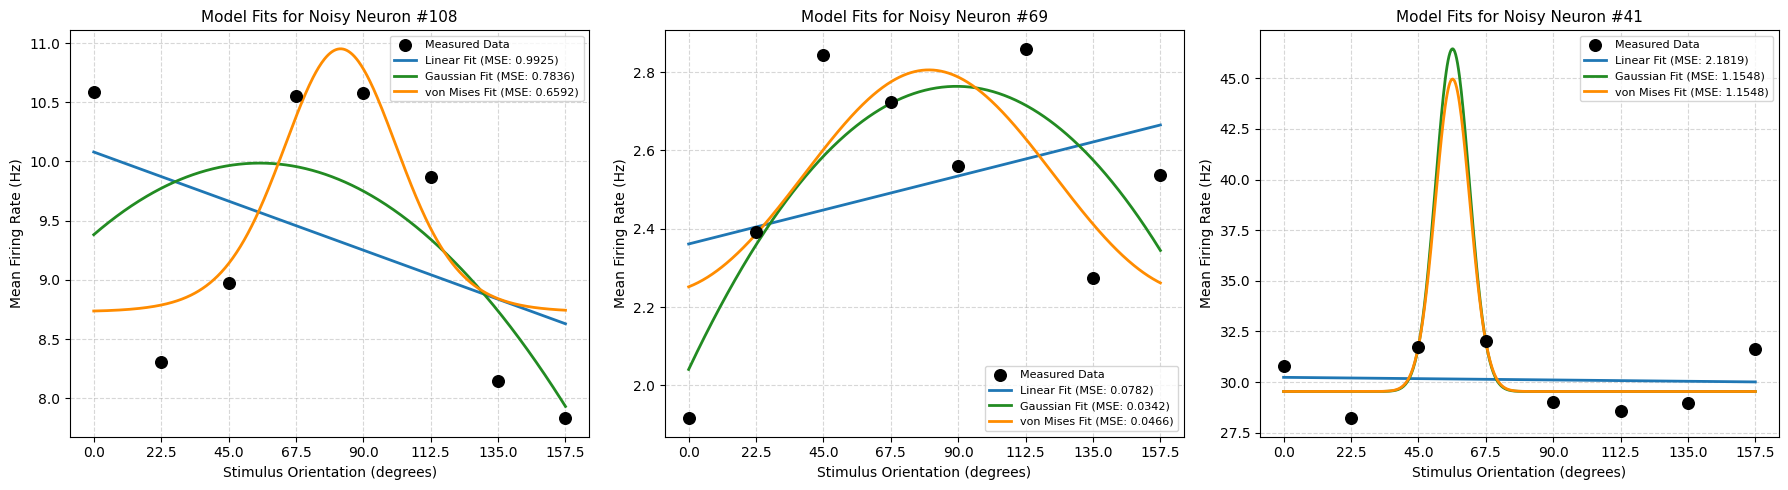

--- Training Error Comparison for Noisiest Neurons ---


Unit ID,Tuning SNR,Linear MSE (Hz^2),Gaussian MSE (Hz^2),von Mises MSE (Hz^2)
Neuron #108,13.21,0.9925,0.7836,0.6592
Neuron #69,11.54,0.0782,0.0342,0.0466
Neuron #41,10.81,2.1819,1.1548,1.1548


In [60]:
# =============================================================================
# CELL 8: EXTENDED EVALUATION - LINEAR, GAUSSIAN, AND VON MISES MODELS
# =============================================================================

# Use the three noisiest neurons selected in Cell 3
noisier_neurons = bottom_3_noisy

extended_results = []

fig, axes = plt.subplots(1, len(noisier_neurons), figsize=(18, 5))

# Ensure axes is iterable even if only one neuron is selected
if len(noisier_neurons) == 1:
    axes = [axes]

for i, idx in enumerate(noisier_neurons):
    y_noisy = tuning_curves[:, idx]

    # 1. Linear model
    coeffs_lin = np.polyfit(x, y_noisy, 1)
    y_pred_lin = np.polyval(coeffs_lin, x)
    mse_lin = np.mean((y_noisy - y_pred_lin) ** 2)

    # 2. Gaussian model
    try:
        popt_g_n, _ = curve_fit(
            gaussian_tuning,
            x,
            y_noisy,
            p0=[
                max(np.ptp(y_noisy), 1e-6),
                mapped_degrees[np.argmax(y_noisy)],
                30.0,
                np.min(y_noisy)
            ],
            maxfev=10000
        )
        y_pred_g_n = gaussian_tuning(x, *popt_g_n)
        mse_g_n = np.mean((y_noisy - y_pred_g_n) ** 2)
    except Exception:
        popt_g_n = None
        mse_g_n = np.nan

    # 3. Circular von Mises model
    try:
        popt_vm_n, _ = curve_fit(
            von_mises_tuning,
            x,
            y_noisy,
            p0=[
                max(np.min(y_noisy), 0),
                max(np.ptp(y_noisy), 1e-6),
                mapped_degrees[np.argmax(y_noisy)],
                1.0
            ],
            bounds=([0, 0, 0, 0], [np.inf, np.inf, 180, 50]),
            maxfev=10000
        )
        y_pred_vm_n = von_mises_tuning(x, *popt_vm_n)
        mse_vm_n = np.mean((y_noisy - y_pred_vm_n) ** 2)
    except Exception:
        popt_vm_n = None
        mse_vm_n = np.nan

    # Store results
    extended_results.append({
        "Unit ID": f"Neuron #{idx}",
        "Tuning SNR": snr[idx],
        "Linear MSE (Hz^2)": mse_lin,
        "Gaussian MSE (Hz^2)": mse_g_n,
        "von Mises MSE (Hz^2)": mse_vm_n
    })

    # Plot measured data and fitted models
    axes[i].scatter(
        x, y_noisy,
        color="black", s=70,
        label="Measured Data", zorder=5
    )

    axes[i].plot(
        x_fine,
        np.polyval(coeffs_lin, x_fine),
        color="tab:blue", linewidth=2,
        label=f"Linear Fit (MSE: {mse_lin:.4f})"
    )

    if popt_g_n is not None:
        axes[i].plot(
            x_fine,
            gaussian_tuning(x_fine, *popt_g_n),
            color="forestgreen", linewidth=2,
            label=f"Gaussian Fit (MSE: {mse_g_n:.4f})"
        )

    if popt_vm_n is not None:
        axes[i].plot(
            x_fine,
            von_mises_tuning(x_fine, *popt_vm_n),
            color="darkorange", linewidth=2,
            label=f"von Mises Fit (MSE: {mse_vm_n:.4f})"
        )

    axes[i].set_title(f"Model Fits for Noisy Neuron #{idx}", fontsize=11)
    axes[i].set_xlabel("Stimulus Orientation (degrees)", fontsize=10)
    axes[i].set_ylabel("Mean Firing Rate (Hz)", fontsize=10)
    axes[i].set_xticks(x)
    axes[i].legend(fontsize=8)
    axes[i].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Display results table
df_extended = pd.DataFrame(extended_results)

print("--- Training Error Comparison for Noisiest Neurons ---")
display(
    df_extended.style.format({
        "Tuning SNR": "{:.2f}",
        "Linear MSE (Hz^2)": "{:.4f}",
        "Gaussian MSE (Hz^2)": "{:.4f}",
        "von Mises MSE (Hz^2)": "{:.4f}"
    }).hide(axis="index")
)

## Final Interpretation

The main takeaway is that the model with the lowest training MSE is not automatically the best model.

The degree-7 polynomial can fit the eight observed mean responses almost perfectly, but it has little biological interpretability and is likely to overfit. The Gaussian and von Mises models have more parameters than a linear model but far fewer than a degree-7 polynomial, and their parameters correspond to meaningful features of neuronal tuning.

For this neuron, the von Mises model is the most appropriate choice because it is biologically interpretable and explicitly accounts for the circular structure of orientation. Even when its MSE is only slightly different from the Gaussian model, it is preferable in principle because orientation is circular rather than linear.

For noisier neurons, model choice becomes even more important. High flexibility can produce low training error, but it can also fit noise. A simpler constrained model may generalize better and give more reliable estimates of preferred orientation and tuning width.